# Online fault-family DSI with a healthy PCA model — XJTU-SY bearings

Online (causal) version of the fault-signature DSI. Each record is processed when it arrives, and nothing after it is used.

1. **Input**: envelope spectrum of the record (`FEATURE_BAND` = 200–3200 Hz) on an **order axis** (multiples of the estimated shaft frequency ρ·fr; ρ from the first 15 records), as the log10 prominence above the local median floor (`hor` and `ver` concatenated). The order axis makes all bearings and conditions comparable.
2. **Healthy model**: PCA (16 components, standardized input) of the healthy records of the **other bearings of the fleet** (first 15 records of each). PCA is a linear autoencoder; on these data a dense AE gave the same FPTs and the same dominant families, so the simpler model is used.
3. **Detection**: anomaly score = log reconstruction error, in σ units of held-out healthy records. **FPT** = first of 3 consecutive records with the score above the 99.5 % healthy quantile (2.576 σ) **or** a fault-family DSI above 3 σ (`FAMILY_ALARM_THR`), whichever comes first (`FPT_trigger`). The family trigger catches faults that change only a few lines, which the global score dilutes (e.g. the cage fault of Bearing1_4, seen only by `CAGE`). Before the FPT the family DSI uses the nominal orders (κ is estimated only after the FPT), so the trigger is causal.
4. **Tracking**: residual (input − reconstruction) read at the κ-corrected fault orders → one DSI per fault family, in **healthy-σ units** (median / MAD of held-out healthy residuals). κ is re-estimated online every 15 records after the FPT.
5. **Reporting**: every family above 3 σ is reported (`active`, strongest first), not only the strongest one: mixed or successive faults (Bearing2_3: outer race + cage; Bearing2_5: early inner-race defect, then outer race) appear as such. A family DSI is not necessarily monotonic: an early defect can wear smooth or be masked by the rising floor of a later fault (Bearing2_5, BPFI).
6. **CAGE family** (raw spectrum): the cage signature of Bearing1_4 and Bearing2_3 is not impulsive and is not separated by the envelope families (with 8 balls BPFO = 8·FTF, so the envelope cage comb mixes with the outer race). It is visible in the **raw low-frequency spectrum**: lines at FTF, 2·FTF, fr − FTF and fr + FTF (cage imbalance / rub modulating the shaft). `CAGE` = mean log10 prominence of these 4 lines, at the cage correction (±4 %, cage slip) that maximizes it, z-scored with the healthy records of the same fleet as the PCA model. On the 15 bearings, last 30 % of life: Bearing1_4 4.6 σ, Bearing2_3 1.6 σ (95th percentile 5.1 and 2.8), all others ≤ 0.3 σ (95th percentile ≤ 0.7).

**Start check** (handles bearings that are already faulty at the start): from record 1 the bearing is scored by the fleet model. At record 15 its own first records are checked against that model:
- **healthy** start (no fault family > 3 σ in the first 15 records): they are added to the healthy model (fleet + own), which scores records 16 onwards;
- **faulty** start (a fault family > 3 σ, e.g. Bearing3_2, Bearing3_5): they are not added, the fleet model is kept and the FPT is placed within the first 15 records.

The fleet itself is screened the same way: a fleet bearing whose start is faulty (checked with a model without it) is not used as healthy data.

Definitions are those of `teste_R2` (sections 1–4 and the κ correction). Outputs: `Dataset\DSIR4\BearingX_Y.csv` (score, alarm, fpt marker, active families, family DSI per direction `BPFO_hor`, ..., `CAGE_ver` and fused `BPFO`, ..., `CAGE`); spectra cache (envelope spectra and raw cage lines): `Dataset\SpecR4`.

## Definitions from `teste_R2`

Data loading, envelope spectrum, stage layer, demodulation band, fault orders, speed estimate and κ functions, unchanged.

In [2]:
import os
import re
import numpy as np
import pandas as pd
from scipy.stats import kurtosis
from sklearn.covariance import LedoitWolf
from Functions.Graphs import *
from Functions.Utils import *
import seaborn as sns


In [3]:
fs = 25600            # XJTU-SY sampling rate [Hz]

# LDK UEH204 geometry (Wang et al., IEEE Trans. Reliab., 2020)
n_balls, d_ball, D_pitch, alpha = 8, 7.92, 34.55, 0.0

CONDITIONS = {1: (35.0, 12), 2: (37.5, 11), 3: (40.0, 10)}   # X: (shaft frequency fr [Hz], radial load [kN])

DatasetPath = r'C:\Users\Usuario\Desktop\Python\Batteries_Prognostics\Dataset'
OUT_DIRS = {'hor': os.path.join(DatasetPath, 'DSIh'), 'ver': os.path.join(DatasetPath, 'DSIv')}

def bearing_condition(bearing_path):
    '''Operating condition from the folder name BearingX_Y -> (name, fr, load).'''
    name = os.path.basename(os.path.normpath(bearing_path))
    m = re.fullmatch(r'Bearing(\d)_(\d+)', name)
    if m is None or int(m.group(1)) not in CONDITIONS:
        raise ValueError(f'Folder name must be BearingX_Y with X in {list(CONDITIONS)}: {name}')
    fr, load = CONDITIONS[int(m.group(1))]
    return name, fr, load

def load_bearing(bearing_path):
    '''All records (1.csv, 2.csv, ...) of a bearing -> {'hor': (records, samples), 'ver': (records, samples)}.'''
    files = sorted((f for f in os.listdir(bearing_path) if f.endswith('.csv')), key=lambda x: int(x.split('.')[0]))
    first = pd.read_csv(os.path.join(bearing_path, files[0]), usecols=['hor', 'ver'])
    data = np.empty((len(files), len(first), 2), dtype=np.float32)
    for k, f in enumerate(files):
        data[k] = pd.read_csv(os.path.join(bearing_path, f), usecols=['hor', 'ver'])[['hor', 'ver']].values
    return {'hor': data[:, :, 0], 'ver': data[:, :, 1]}

## 1. Characteristic fault frequencies

Only the shaft frequency `fr` changes with the operating condition; the fault orders depend on the bearing geometry.

| Fault | Formula |
|---|---|
| Outer race (BPFO) | (n/2)·fr·(1 − d/D·cosα) |
| Inner race (BPFI) | (n/2)·fr·(1 + d/D·cosα) |
| Ball spin (BSF) | (D/2d)·fr·(1 − (d/D·cosα)²) |
| Cage (FTF) | (1/2)·fr·(1 − d/D·cosα) |

In [4]:
def fault_orders(n, d, D, alpha=0.0):
    '''Characteristic fault frequencies as multiples (orders) of the shaft frequency.'''
    r = d / D * np.cos(np.deg2rad(alpha))
    return {'BPFO': n / 2 * (1 - r),
            'BPFI': n / 2 * (1 + r),
            'BSF': D / (2 * d) * (1 - r**2),
            'FTF': 0.5 * (1 - r)}

ORDERS = fault_orders(n_balls, d_ball, D_pitch, alpha)
pd.DataFrame({f'{fr} Hz': {k: o * fr for k, o in ORDERS.items()} for fr, _ in CONDITIONS.values()}).round(2)

,35.0 Hz,37.5 Hz,40.0 Hz
BPFO,107.91,115.62,123.32
BPFI,172.09,184.38,196.68
BSF,72.33,77.50,82.66
FTF,13.49,14.45,15.42


## 2. Stage layer: DSI and FPT

DSI = Mahalanobis distance (Ledoit-Wolf covariance) of a feature vector [log RMS, log kurtosis, log envelope-band energies] to the healthy baseline (first `n_base` records), in baseline-σ units and EWMA-smoothed. FPT = first of 3 consecutive records with DSI > 3σ. The FPT defines the degraded records used to select the demodulation band.

In [5]:
def envelope(x, band=None, fs=fs):
    '''Envelope via analytic signal; the band-pass is done in the frequency domain.'''
    N = len(x)
    S = np.fft.fft(x - x.mean())
    f = np.fft.fftfreq(N, 1 / fs)
    H = np.zeros(N)
    H[f > 0] = 2.0
    if band is not None:
        H[(f < band[0]) | (f > band[1])] = 0.0
    return np.abs(np.fft.ifft(S * H))

def envelope_spectrum(x, band=None, fs=fs):
    '''Amplitude spectrum of the envelope.'''
    env = envelope(x, band, fs)
    env = env - env.mean()
    E = np.abs(np.fft.rfft(env * np.hanning(len(env)))) * 2 / len(env)
    return np.fft.rfftfreq(len(env), 1 / fs), E

def stage_features(x, n_bands=16, fmax=1000):
    '''log RMS, log kurtosis and log band energies of the envelope spectrum (0-fmax Hz).'''
    f, E = envelope_spectrum(x)
    edges = np.linspace(0, fmax, n_bands + 1)
    bands = [np.sum(E[(f >= a) & (f < b)]**2) for a, b in zip(edges[:-1], edges[1:])]
    rms = np.sqrt(np.mean(x**2))
    return np.r_[np.log10(rms), np.log10(kurtosis(x, fisher=False)), np.log10(np.array(bands) + 1e-12)]

def dsi_md(F, n_base=15, lam=0.3):
    '''Mahalanobis distance to the healthy baseline, in baseline-sigma units, EWMA-smoothed (causal).'''
    lw = LedoitWolf().fit(F[:n_base])
    md = np.sqrt(lw.mahalanobis(F))
    md = (md - md[:n_base].mean()) / md[:n_base].std()
    ewma = np.zeros_like(md)
    for i in range(len(md)):
        ewma[i] = lam * md[i] + (1 - lam) * (ewma[i - 1] if i else md[i])
    return md, ewma

def detect_fpt(dsi, thr=3.0, n_consec=3, start=0):
    '''First record of n_consec consecutive values above thr (avoids triggers by random noise).'''
    above = dsi > thr
    for k in range(start, len(dsi) - n_consec + 1):
        if above[k:k + n_consec].all():
            return k
    return None

## 3. Demodulation band (kurtogram-like)

Fault impacts excite a structural resonance; demodulating around it reveals the fault frequencies in the envelope spectrum. The band is chosen on a dyadic grid by maximizing the spectral kurtosis of the squared envelope over the degraded records (Antoni, 2007). Bands above 0.9·Nyquist are excluded (anti-aliasing region).

In [6]:
def band_grid(fr, fs=fs, levels=(1, 2, 3, 4, 5, 6), fmin=200, fmax_ratio=0.9):
    '''Dyadic band grid (1/2^level of the Nyquist band), avoiding the anti-aliasing region.'''
    grid = []
    for lv in levels:
        bw = fs / 2 / 2**lv
        for i in range(2**lv):
            lo, hi = max(i * bw, fmin), (i + 1) * bw
            if hi - lo > 4 * max(ORDERS.values()) * fr and hi <= fmax_ratio * fs / 2:
                grid.append((lo, hi))
    return grid

def select_band(Xd, grid):
    '''Kurtogram criterion: band maximizing the spectral kurtosis (of the squared envelope) over degraded records.'''
    def sk(x, b):
        e2 = envelope(x, b)**2
        return np.mean(e2**2) / np.mean(e2)**2 - 2
    score = np.array([np.mean([sk(x, b) for x in Xd]) for b in grid])
    return grid[int(np.argmax(score))], score

## 4. Fault signature vector

For each characteristic order (BPFO, BPFI, BSF, FTF) and its harmonics 1–3×, plus the BPFI ±fr and 2·BSF ±FTF sidebands: the peak within ±3 % (slip) of the envelope spectrum relative to its local median (noise floor), in log10. Each feature is then z-scored with the healthy baseline (first `n_base` records) → `Z`.

In [7]:
def peak_ratio(f, E, fc, tol=0.025, floor_win=0.2):
    '''Peak within ±tol of fc relative to the local median (noise floor) of the envelope spectrum.'''
    win = (f > fc * (1 - tol)) & (f < fc * (1 + tol))
    if not win.any():                       # window narrower than one bin (e.g. FTF): nearest bin
        win = np.abs(f - fc) == np.abs(f - fc).min()
    ref = (f > fc * (1 - floor_win)) & (f < fc * (1 + floor_win))
    return E[win].max() / (np.median(E[ref]) + 1e-12)

def fault_signature(x, band, fr, n_harm=3):
    f, E = envelope_spectrum(x, band)
    feats = {}
    for name, o in ORDERS.items():
        for h in range(1, n_harm + 1):
            feats[f'{name}_{h}x'] = np.log10(peak_ratio(f, E, h * o * fr))
    for s in (-1, 1):   # inner race: shaft-rate sidebands (load-zone modulation)
        feats[f'BPFI_sb{s:+d}'] = np.log10(peak_ratio(f, E, ORDERS['BPFI'] * fr + s * fr))
    for s in (-1, 1):   # rolling element: cage-rate sidebands
        feats[f'BSF_sb{s:+d}'] = np.log10(peak_ratio(f, E, 2 * ORDERS['BSF'] * fr + s * ORDERS['FTF'] * fr))
    feats['fr_1x'] = np.log10(peak_ratio(f, E, fr))
    return feats

## Harmonic-consistent correction of the fault frequencies (κ)

In damaged bearings the fault lines sit slightly away from the kinematic value. Two effects add up, and both are proportional (the same percentage for every harmonic):

1. **Shaft speed**: the real speed is ~1–2.5 % below the nominal one (motor slip under load). It is estimated per bearing as ρ·fr, with ρ ∈ [0.97, 1.03] (restricted to ±1 bin around the 1× shaft line, so that another comb cannot pull it away, as the BPFO comb of Bearing3_5 did) maximizing the prominence of the shaft harmonics m·fr (m = 1..10) in the **raw** spectrum of the healthy baseline records (first `n_base`), jointly for `hor` and `ver`. If ρ falls on the edge of the search range or < 5 harmonics are clear, ρ = 1.
2. **Fault order**: for each fault type, κ ∈ [0.95, 1.05] maximizes the log prominence of the harmonics κ·h·order·ρ·fr (h = 1..3; FTF: h = 1..6), summed over the **last (up to 20) contiguous blocks of 15 records after the FPT** (mean envelope spectrum of each block, shaft harmonics masked, `hor` and `ver` jointly). A real line keeps the same κ from block to block; noise does not. A block is *clear* at κ if ≥ 2 harmonics exceed 2× the noise floor or the 1× exceeds 4×. κ is accepted if ≥ 2 blocks are clear.

Features of a fault type with an accepted κ use a ±1 % window around the corrected frequencies; the other fault types keep the nominal order and the fixed ±2.5 % window (never worse than the fixed method). `BSF_3x` is excluded: 3·BSF and 2·BPFO are 0.5 % apart and measure the same peak. Speed, band and κ use the whole record (offline, like the band selection).

**Demodulation band**: the fault features and κ use a fixed wide low band, `FEATURE_BAND` = 200–3200 Hz (on the 15 XJTU-SY bearings the fault lines are much clearer there than in the max-kurtosis band, which tracks impulsiveness). The FTF features are also measured in the max-kurtosis band, with a κ estimated in that band (`FTFsk_*`): the weak cage signature of Bearing1_4 is visible only there.

**FTF** features: harmonics 1x–6x and the shaft-rate modulation fr ± FTF (`FTF_sb±1`). BPFO = 8·FTF (8 balls): an outer-race line is also the 8th cage harmonic.

**Baseline**: Z is relative to the bearing's own first `n_base` records, which assumes they are healthy. Bearing3_5 (BPFO ×10 above the floor from minute 1) and Bearing3_2 (BPFI ×10) are already faulty there, so two baseline-free indicators are saved as well:
- **P** (`Dataset\DSIhP`, `Dataset\DSIvP`): the log10 prominence itself (peak / local floor). A pure-noise window gives ~0.2–0.4 (×1.5–2.5); > 0.7 (×5) means a line is present.
- **Pooled Z** (`compute_Z_pooled` → `Dataset\DSIhPool`, `Dataset\DSIvPool`): z relative to the first `n_base` records of the *other* bearings of the same condition (leave-one-out, median and 1.4826·MAD, robust to one faulty baseline among them). Run it after `compute_Z_k` for all bearings.

Z is saved at `Dataset\DSIhK\BearingX_Y.csv` and `Dataset\DSIvK\BearingX_Y.csv` (29 columns; the fixed-window `DSIh` / `DSIv` files are kept).

In [8]:
OUT_DIRS_K = {'hor': os.path.join(DatasetPath, 'DSIhK'), 'ver': os.path.join(DatasetPath, 'DSIvK')}         # z, own baseline
OUT_DIRS_P = {'hor': os.path.join(DatasetPath, 'DSIhP'), 'ver': os.path.join(DatasetPath, 'DSIvP')}         # log10 prominence
OUT_DIRS_POOL = {'hor': os.path.join(DatasetPath, 'DSIhPool'), 'ver': os.path.join(DatasetPath, 'DSIvPool')}  # z, pooled baseline
FEATURE_BAND = (200.0, 3200.0)   # demodulation band of the fault features and of kappa (the fault lines are much clearer
                                 # here than in the max-kurtosis band, which tracks impulsiveness rather than fault lines)
N_HARM = {'BPFO': 3, 'BPFI': 3, 'BSF': 3, 'FTF': 6}   # cage: 1x is 1 bin (~5 %) wide, the 4x-6x harmonics are the clearest

def peak_ratio_k(f, E, fc, tol=0.01, floor_win=0.2):
    '''Peak within ±tol of fc (at least ±1 frequency bin) relative to the local median (noise floor).'''
    df = f[1] - f[0]
    win = np.abs(f - fc) <= max(tol * fc, df)
    ref = np.abs(f - fc) <= floor_win * fc
    return E[win].max() / (np.median(E[ref]) + 1e-12)

def prominence_curve(f, E, fcs, tol=0.005, floor_win=0.2):
    '''peak_ratio_k for an array of centre frequencies fcs, evaluated only on the spectrum region around them.'''
    sl = (f >= fcs.min() * (1 - floor_win) - 2 * (f[1] - f[0])) & (f <= fcs.max() * (1 + floor_win) + 2 * (f[1] - f[0]))
    fs_, Es_ = f[sl], E[sl]
    return np.array([peak_ratio_k(fs_, Es_, fc, tol, floor_win) for fc in fcs])

def raw_spectrum(x, fs=fs):
    x = x - x.mean()
    return np.fft.rfftfreq(len(x), 1 / fs), np.abs(np.fft.rfft(x * np.hanning(len(x))))

def onset_and_band(X, fr, n_base=15, max_band_records=50):
    '''Stage layer (DSI, FPT) and demodulation band, as in compute_Z_direction.'''
    F_stage = np.array([stage_features(x) for x in X])
    _, dsi = dsi_md(F_stage, n_base=n_base)
    fpt = detect_fpt(dsi, start=n_base)
    k0 = fpt if fpt is not None else int(0.8 * len(X))       # no onset detected: last 20 % of life
    idx = np.unique(np.linspace(k0, len(X) - 1, min(max_band_records, len(X) - k0)).astype(int))
    band, _ = select_band(X[idx], band_grid(fr))
    return fpt, band

def estimate_speed_comb(Xb, fr, rhos=np.arange(0.97, 1.0301, 0.0005), n=10, tol=0.002, min_prom=2.0, min_harm=5):
    '''Real shaft frequency rho*fr from the shaft harmonics m*fr of the raw spectrum of the healthy records
    Xb = {'hor': ..., 'ver': ...} (joint score of both directions). rho = 1 if not found or on the grid edge.'''
    f = raw_spectrum(Xb['hor'][0])[0]
    score, P = 0, []
    for X in Xb.values():
        E = np.mean([raw_spectrum(x)[1] for x in X], axis=0)
        P.append(np.array([prominence_curve(f, E, rhos * m * fr, tol) for m in range(1, n + 1)]).T)
        score = score + np.log10(P[-1]).sum(axis=1)
    i = int(np.argmax(score))
    ok = (np.sqrt(P[0][i] * P[1][i]) > min_prom).sum() >= min_harm and 0 < i < len(rhos) - 1
    return rhos[i] if ok else 1.0

def estimate_speed(Xb, fr, rhos=np.arange(0.97, 1.0301, 0.0005), n=10, tol=0.002, min_prom=2.0, min_harm=5, win=0.06):
    '''estimate_speed_comb restricted to +-1 bin around the strongest raw line within +-win of fr (the 1x shaft line),
    so that another comb cannot pull the estimate away (Bearing3_5: 1x at 39.84 Hz, but a strong BPFO comb at
    124.2 Hz ~ 3 x 41.4 Hz gave 41.18 Hz with the free search). If the comb fails, the 1x line itself.'''
    f = raw_spectrum(Xb['hor'][0])[0]
    df = f[1] - f[0]
    E = sum(np.mean([raw_spectrum(x)[1] for x in X], axis=0) for X in Xb.values())
    near = np.where(np.abs(f - fr) <= win * fr)[0]
    f1 = f[near[np.argmax(E[near])]]
    sub = rhos[np.abs(rhos * fr - f1) <= df]
    rho = estimate_speed_comb(Xb, fr, sub, n, tol, min_prom, min_harm) if len(sub) >= 3 else 1.0
    return rho if rho != 1.0 else (f1 / fr if abs(f1 / fr - 1) < 0.03 else 1.0)

def mask_lines(f, E, lines, tol=0.005):
    '''Bins within ±tol (at least ±1 bin) of each line replaced by the spectrum median.'''
    E = E.copy()
    df, med = f[1] - f[0], np.median(E)
    for fl in lines:
        E[np.abs(f - fl) <= max(tol * fl, df)] = med
    return E

def mask_shaft_harmonics(f, E, fr, n=16, tol=0.005):
    '''Shaft harmonics m*fr masked, so that the fault features (and kappa) do not lock on them.'''
    return mask_lines(f, E, [m * fr for m in range(1, n + 1)], tol)

def fault_lines(name, o, fr, n_harm=None, n_sb=1):
    '''Lines of the fault family `name` (o: fault orders): harmonics h*o*fr and their shaft-rate sidebands
    (±1..n_sb * fr); for BSF also 2*BSF ± FTF. n_harm: N_HARM[name] by default.'''
    n_harm = n_harm or N_HARM[name]
    lines = [h * o[name] * fr + s * fr for h in range(1, n_harm + 1) for s in range(-n_sb, n_sb + 1)]
    if name == 'BSF':
        lines += [2 * o['BSF'] * fr + s * o['FTF'] * fr for s in (-1, 1)]
    return lines

def corrected_orders(kappa):
    return {k: v * (kappa[k] or 1.0) for k, v in ORDERS.items()}

def kappa_blocks(n_records, k0, block=15, max_blocks=20):
    '''Start indices of the last (at most max_blocks) contiguous blocks of `block` records between k0 and the end of life.'''
    starts = np.arange(n_records - block, k0 - 1, -block)[:max_blocks][::-1]
    return starts if len(starts) else np.array([max(0, n_records - block)])

def estimate_kappa(D, bands, fr, k0, kappas=np.arange(0.95, 1.0501, 0.001), tol=0.005,
                   block=15, max_blocks=20, min_prom=2.0, strong_prom=4.0, min_blocks=2):
    '''Harmonic-consistent correction of each fault order, from blocks of `block` records after k0.
    For each block, the mean envelope spectrum (shaft harmonics masked) gives the log prominence of the harmonics
    kappa*h*order*fr, jointly for D = {'hor': ..., 'ver': ...} (each direction in its own band). kappa maximizes the
    score summed over the blocks: a real line keeps the same kappa from block to block, noise does not.
    A block is "clear" at kappa if >= 2 harmonics exceed min_prom x floor or the 1x exceeds strong_prom x floor;
    kappa is accepted if >= min_blocks blocks are clear, otherwise None (nominal order and the fixed window are kept).
    Cross-talk: the fault types are accepted one at a time, strongest first (most clear blocks); the lines of the
    accepted types (fault_lines) are masked before kappa is searched again for the remaining types.
    Returns kappa, score, kappas, n_clear and `order` (accepted types, strongest first).'''
    starts = kappa_blocks(len(next(iter(D.values()))), k0, block, max_blocks)
    spectra = {}
    for d, X in D.items():
        f = envelope_spectrum(X[0], bands[d])[0]
        spectra[d] = (f, [mask_shaft_harmonics(f, np.mean([envelope_spectrum(x, bands[d])[1]
                                                            for x in X[s0:s0 + block]], axis=0), fr) for s0 in starts])

    def search(names, lines):
        L = {k: np.zeros((len(starts), len(kappas), N_HARM[k])) for k in names}   # mean log10 prominence (hor, ver)
        for f, blocks in spectra.values():
            for b, E in enumerate(blocks):
                E = mask_lines(f, E, lines)
                for name in names:
                    for h in range(1, N_HARM[name] + 1):
                        L[name][b, :, h - 1] += np.log10(prominence_curve(f, E, kappas * h * ORDERS[name] * fr, tol)) / len(D)
        res = {}
        for name in names:
            s = L[name].sum(axis=(0, 2))
            i = int(np.argmax(s))
            P = 10 ** L[name][:, i, :]                                          # (blocks, harmonics) at kappa
            n_ok = int((((P > min_prom).sum(axis=1) >= 2) | (P[:, 0] > strong_prom)).sum())
            res[name] = (kappas[i], s, n_ok, n_ok >= min(min_blocks, len(starts)))
        return res

    kappa = {k: None for k in ORDERS}
    score, n_clear, order, lines, remaining = {}, {}, [], [], list(ORDERS)
    while remaining:
        res = search(remaining, lines)
        for k in remaining:
            score[k], n_clear[k] = res[k][1], res[k][2]
        accepted = [k for k in remaining if res[k][3]]
        if not accepted:
            break
        best = max(accepted, key=lambda k: (res[k][2], res[k][1].max()))
        kappa[best] = res[best][0]
        order.append(best)
        remaining.remove(best)
        lines += fault_lines(best, corrected_orders(kappa), fr)
    return kappa, score, kappas, n_clear, order

def fault_signature_k(x, band, fr, kappa, order=(), sk=None, tol=0.01, tol_fixed=0.025, exclude=('BSF_3x',)):
    '''Same features as fault_signature at the kappa-corrected fault frequencies: ±tol window for the fault types
    with an accepted kappa, nominal order and ±tol_fixed window otherwise. Shaft harmonics are masked (except for
    fr_1x), and each fault type is measured with the lines of the stronger accepted types (`order`) masked.
    FTF: harmonics 1x-6x (N_HARM) and the shaft-rate modulation fr ± FTF. sk = (band_sk, kappa_sk, order_sk): the FTF
    features are also measured in the max-kurtosis band, with the kappa estimated in that band (FTFsk_*): a weak cage
    signature (e.g. Bearing1_4) may be visible only there.
    `exclude`: features that cannot be told apart from another one (3*BSF and 2*BPFO are 0.5 % apart).'''
    f, E0 = envelope_spectrum(x, band)
    Es = mask_shaft_harmonics(f, E0, fr)
    o = corrected_orders(kappa)
    w = {k: tol if kappa[k] is not None else tol_fixed for k in ORDERS}
    E = {}
    for name in ORDERS:
        stronger = order[:order.index(name)] if name in order else order
        E[name] = mask_lines(f, Es, [fl for k in stronger for fl in fault_lines(k, o, fr)])
    feats = {}
    for name in ORDERS:
        for h in range(1, N_HARM[name] + 1):
            feats[f'{name}_{h}x'] = np.log10(peak_ratio_k(f, E[name], h * o[name] * fr, w[name]))
    for s in (-1, 1):   # inner race: shaft-rate sidebands (load-zone modulation)
        feats[f'BPFI_sb{s:+d}'] = np.log10(peak_ratio_k(f, E['BPFI'], o['BPFI'] * fr + s * fr, w['BPFI']))
    for s in (-1, 1):   # rolling element: cage-rate sidebands
        feats[f'BSF_sb{s:+d}'] = np.log10(peak_ratio_k(f, E['BSF'], 2 * o['BSF'] * fr + s * o['FTF'] * fr, w['BSF']))
    for s in (-1, 1):   # cage: modulation of the shaft rate (fr ± FTF)
        feats[f'FTF_sb{s:+d}'] = np.log10(peak_ratio_k(f, E['FTF'], fr + s * o['FTF'] * fr, w['FTF']))
    if sk is not None:
        band_sk, kappa_sk, order_sk = sk
        feats.update({'FTFsk' + k[3:]: v for k, v in fault_signature_k(x, band_sk, fr, kappa_sk, order_sk).items()
                      if k.startswith('FTF_')})
    feats['fr_1x'] = np.log10(peak_ratio_k(f, E0, fr, tol_fixed))
    return {k: v for k, v in feats.items() if k not in exclude}

def corrections(D, fr, n_base=15, block=15, max_blocks=20, band=FEATURE_BAND):
    '''FPT and max-kurtosis band (bands_sk) per direction, feature band (bands, `band` for both directions), real
    shaft frequency, kappa per fault type and order of the accepted types, estimated in the feature band (kappa,
    order) and in the max-kurtosis band (kappa_sk, order_sk; used for FTFsk_*).'''
    fpt, bands_sk = {}, {}
    for d, X in D.items():
        fpt[d], bands_sk[d] = onset_and_band(X, fr, n_base)
    bands = {d: band for d in D}
    n = len(D['hor'])
    k0 = min(v if v is not None else int(0.8 * n) for v in fpt.values())    # earliest onset of the two directions
    fr_e = estimate_speed({d: X[:n_base] for d, X in D.items()}, fr) * fr
    kappa, score, kappas, n_clear, order = estimate_kappa(D, bands, fr_e, k0, block=block, max_blocks=max_blocks)
    kappa_sk, _, _, _, order_sk = estimate_kappa(D, bands_sk, fr_e, k0, block=block, max_blocks=max_blocks)
    return fpt, bands, bands_sk, fr_e, kappa, score, kappas, n_clear, order, kappa_sk, order_sk

def compute_Z_k(bearing_path, out_dirs=OUT_DIRS_K, sig_dirs=OUT_DIRS_P, n_base=15, block=15, max_blocks=20,
                band=FEATURE_BAND, ftf_sk=True):
    '''Speed- and kappa-corrected features of the horizontal and vertical vibration, saved as BearingX_Y.csv in
    out_dirs[direction]: Z, z-score w.r.t. the bearing's own first n_base records;
    sig_dirs[direction]: P, log10 prominence (peak / local floor), independent of any baseline (a pure-noise window
    gives ~0.3-0.5, i.e. x2-3; > 0.7 (x5) means a line is present). Useful when the fault already exists in the first
    records (Bearing3_2, Bearing3_5); see also compute_Z_pooled.
    ftf_sk: also the FTF features in the max-kurtosis band (FTFsk_*).'''
    name, fr, load = bearing_condition(bearing_path)
    D = load_bearing(bearing_path)
    fpt, bands, bands_sk, fr_e, kappa, _, _, n_clear, order, kappa_sk, order_sk = corrections(D, fr, n_base, block, max_blocks, band)
    kap = {k: (f'{100 * (v - 1):+.1f}%' if v is not None else '-') + f' ({n_clear[k]} blocks)' for k, v in kappa.items()}
    k_sk = f"{100 * (kappa_sk['FTF'] - 1):+.1f}%" if kappa_sk['FTF'] is not None else '-'
    print(f'{name}: fr = {fr} Hz, {load} kN, real fr = {fr_e:.2f} Hz ({100 * (fr_e / fr - 1):+.2f}%), '
          f'kappa - 1 = {kap}, accepted (strongest first) = {order}; '
          f'max-kurtosis band: FTF kappa - 1 = {k_sk}, accepted = {order_sk}')

    results = {}
    for d, X in D.items():
        SIG = pd.DataFrame([fault_signature_k(x, bands[d], fr_e, kappa, order, (bands_sk[d], kappa_sk, order_sk) if ftf_sk else None) for x in X], index=np.arange(1, len(X) + 1))
        # z-score relative to the healthy baseline: "how many baseline sigmas above normal"
        Z = (SIG - SIG.iloc[:n_base].mean()) / (SIG.iloc[:n_base].std() + 1e-6)
        Z.index.name = SIG.index.name = 't'
        for dirs, df in ((out_dirs, Z), (sig_dirs, SIG)):
            os.makedirs(dirs[d], exist_ok=True)
            df.to_csv(os.path.join(dirs[d], f'{name}.csv'))
        results[d] = Z
        fpt_t = fpt[d] + 1 if fpt[d] is not None else None
        print(f'  {d}: {len(Z)} records, FPT t = {fpt_t}, feature band {bands[d][0]:.0f}-{bands[d][1]:.0f} Hz, '
              f'max-kurtosis band {bands_sk[d][0]:.0f}-{bands_sk[d][1]:.0f} Hz')
    return results

def compute_Z_pooled(sig_dirs=OUT_DIRS_P, out_dirs=OUT_DIRS_POOL, n_base=15):
    '''Z w.r.t. a pooled healthy baseline, for bearings whose own first records are already faulty: for each
    prominence file P in sig_dirs, the baseline is the first n_base records of the OTHER bearings of the same
    condition (leave-one-out), with robust statistics (median, 1.4826 x MAD) so that a faulty baseline among them
    (e.g. Bearing3_2) does not shift it. Run after compute_Z_k for all bearings of a condition.'''
    results = {}
    for d in sig_dirs:
        P = {os.path.splitext(f)[0]: pd.read_csv(os.path.join(sig_dirs[d], f), index_col=0)
             for f in sorted(os.listdir(sig_dirs[d])) if f.endswith('.csv')}
        os.makedirs(out_dirs[d], exist_ok=True)
        for name, S in P.items():
            cond = bearing_condition(name)[1]
            pool = [Q.iloc[:n_base] for o, Q in P.items() if o != name and bearing_condition(o)[1] == cond]
            if not pool:
                print(f'  {d} {name}: no other bearing of the same condition, skipped')
                continue
            pool = pd.concat(pool)[S.columns]
            mu = pool.median()
            sd = 1.4826 * (pool - mu).abs().median()
            Z = (S - mu) / (sd + 1e-6)
            Z.to_csv(os.path.join(out_dirs[d], f'{name}.csv'))
            results[(d, name)] = Z
        print(f'{d}: pooled Z for {len([k for k in results if k[0] == d])} bearings -> {out_dirs[d]}')
    return results


## Online DSI (PCA healthy model)

In [9]:
from sklearn.decomposition import PCA
from scipy.ndimage import median_filter
import matplotlib.pyplot as plt

R4_CACHE = os.path.join(DatasetPath, 'SpecR4')    # envelope spectra per bearing (npz)
R4_OUT = os.path.join(DatasetPath, 'DSIR4')       # online DSI per bearing (csv)
N_BASE_R4 = 15             # healthy records per bearing (first 15 minutes)
BLOCK_R4 = 15              # kappa blocks after the FPT
Q995 = 2.576               # one-sided 99.5 % quantile of the standard normal
FAMILY_START_THR = 3.0     # faulty start: a fault family above 3 healthy sigmas in the first records
FAMILY_ALARM_THR = 3.0     # FPT trigger and reporting: a fault family above 3 healthy sigmas
ORDER_STEP = 0.025
ORDER_GRID = np.arange(0.25, 20.0 + 1e-9, ORDER_STEP)
NG = len(ORDER_GRID)
FMAX_R4 = 1000.0
FAMILIES = list(ORDERS)                 # envelope families (PCA residual)
FAMILIES_DSI = FAMILIES + ['CAGE']      # + cage lines in the raw spectrum
CAGE_KAPPAS = np.arange(0.96, 1.0401, 0.002)   # cage slip: correction of FTF searched within ±4 %

def cage_raw_lines(x, fr_e, fmax=200.0):
    '''log10 prominence of the cage lines FTF, 2·FTF, fr − FTF, fr + FTF in the raw spectrum (0-fmax Hz), at the cage
    correction (CAGE_KAPPAS) maximizing their mean. Returns the 4 values.'''
    f, E = raw_spectrum(x)
    keep = f <= fmax
    f, E = f[keep], E[keep]
    c = CAGE_KAPPAS * ORDERS['FTF'] * fr_e
    P = np.log10(np.array([[peak_ratio_k(f, E, fc, 0.003) for fc in (ci, 2 * ci, fr_e - ci, fr_e + ci)] for ci in c]))
    return P[int(np.argmax(P.mean(axis=1)))]

def bearing_spectra(bearing_path, cache_dir=R4_CACHE, n_base=N_BASE_R4):
    '''Envelope spectrum (FEATURE_BAND, 0-FMAX_R4 Hz) of every record and direction, the real shaft frequency
    (estimate_speed on the first n_base records) and the raw cage lines (cage_raw_lines, C_hor / C_ver).
    Computed once and cached as <cache_dir>\\BearingX_Y.npz (a cache without the cage lines is completed).'''
    name = os.path.basename(os.path.normpath(bearing_path))
    out = os.path.join(cache_dir, name + '.npz')
    z = dict(np.load(out)) if os.path.exists(out) else {}
    if 'C_hor' not in z:
        _, fr, _ = bearing_condition(bearing_path)
        D = load_bearing(bearing_path)
        if 'E_hor' not in z:
            f = envelope_spectrum(D['hor'][0], FEATURE_BAND)[0]
            keep = f <= FMAX_R4
            z['f'] = f[keep]
            for d, X in D.items():
                z['E_' + d] = np.array([envelope_spectrum(x, FEATURE_BAND)[1][keep] for x in X], dtype=np.float32)
            z['fr_e'] = estimate_speed({d: X[:n_base] for d, X in D.items()}, fr) * fr
        for d, X in D.items():
            z['C_' + d] = np.array([cage_raw_lines(x, float(z['fr_e'])) for x in X], dtype=np.float32)
        os.makedirs(cache_dir, exist_ok=True)
        np.savez(out, **z)
    return {'f': z['f'].astype(np.float64), 'E_hor': z['E_hor'], 'E_ver': z['E_ver'], 'fr_e': float(z['fr_e']),
            'C_hor': z['C_hor'], 'C_ver': z['C_ver']}

def order_prominence(f, E, fr_e, floor_orders=1.0):
    '''log10(peak / local median floor) on ORDER_GRID: each grid point takes the max of the envelope spectrum over
    its cell (at least ±0.6 bin); the floor is the median over ±floor_orders.'''
    df = f[1] - f[0]
    hw = max(0.5 * ORDER_STEP * fr_e, 0.6 * df)
    lo = np.searchsorted(f, ORDER_GRID * fr_e - hw)
    hi = np.searchsorted(f, ORDER_GRID * fr_e + hw, side='right')
    S = np.stack([E[:, a:b].max(axis=1) for a, b in zip(lo, hi)], axis=1).astype(np.float64)
    floor = median_filter(S, size=(1, int(2 * floor_orders / ORDER_STEP) + 1), mode='nearest')
    return np.log10(S / (floor + 1e-12))

def model_input(spec):
    '''Order-domain prominence spectra of hor and ver, concatenated: (records, 2 * NG).'''
    return np.hstack([order_prominence(spec['f'], spec['E_' + d], spec['fr_e']) for d in ('hor', 'ver')])

## Stage 2 features: fault families on the residual

Same layout as `fault_signature_k`, in order units: harmonics h = 1..`N_HARM` (`BSF_3x` excluded), BPFI ± 1 order, 2·BSF ± FTF, 1 ± FTF. Each feature is the max of the residual within ±1 % (accepted κ) or ±2.5 % (nominal order). Shaft harmonics and the lines of the stronger accepted families are masked. The family DSI is the mean of its features, z-scored with the healthy statistics of the same window case.

In [10]:
def kappa_from_blocks(spectra, fr, kappas=np.arange(0.95, 1.0501, 0.001), tol=0.005, min_prom=2.0,
                      strong_prom=4.0, min_blocks=2):
    '''estimate_kappa on precomputed block-mean spectra {d: (f, [E_block, ...])} (same criteria).'''
    nb = len(next(iter(spectra.values()))[1])
    def search(names, lines):
        L = {k: np.zeros((nb, len(kappas), N_HARM[k])) for k in names}
        for f, blocks in spectra.values():
            for bi, E in enumerate(blocks):
                E = mask_lines(f, E, lines)
                for name in names:
                    for h in range(1, N_HARM[name] + 1):
                        L[name][bi, :, h - 1] += np.log10(prominence_curve(f, E, kappas * h * ORDERS[name] * fr, tol)) / len(spectra)
        res = {}
        for name in names:
            s = L[name].sum(axis=(0, 2))
            i = int(np.argmax(s))
            P = 10 ** L[name][:, i, :]
            n_ok = int((((P > min_prom).sum(axis=1) >= 2) | (P[:, 0] > strong_prom)).sum())
            res[name] = (kappas[i], n_ok, n_ok >= min(min_blocks, nb), s.max())
        return res
    kappa, order, lines, remaining = {k: None for k in ORDERS}, [], [], list(ORDERS)
    while remaining:
        res = search(remaining, lines)
        acc = [k for k in remaining if res[k][2]]
        if not acc:
            break
        best = max(acc, key=lambda k: (res[k][1], res[k][3]))
        kappa[best] = res[best][0]
        order.append(best)
        remaining.remove(best)
        lines += fault_lines(best, corrected_orders(kappa), fr)
    return kappa, order

def kappa_online(spec, fpt, block=BLOCK_R4, max_blocks=20):
    '''(kappa, order) valid at each record: nominal before; updated when each block of `block` records after the
    FPT is complete (from the 2nd block on), from the last (at most max_blocks) completed blocks.'''
    n = len(spec['E_hor'])
    nominal = ({k: None for k in ORDERS}, [])
    state = [nominal] * n
    if fpt is None:
        return state, []
    f, fr_e = spec['f'], spec['fr_e']
    bm = {d: [] for d in ('hor', 'ver')}
    updates, cur = [], nominal
    for t in range(fpt, n):
        if (t - fpt + 1) % block == 0:
            for d in bm:
                bm[d].append(mask_shaft_harmonics(f, spec['E_' + d][t - block + 1:t + 1].astype(np.float64).mean(0), fr_e))
            if len(bm['hor']) >= 2:
                cur = kappa_from_blocks({d: (f, v[-max_blocks:]) for d, v in bm.items()}, fr_e)
                updates.append((t, cur))
        state[t] = cur
    return state, updates

def family_features(r, kappa, order, tol=0.01, tol_fixed=0.025, tol_mask=0.005):
    '''Fault-family features of a residual r on ORDER_GRID (one direction).'''
    r = r.copy()
    for m in range(1, 21):
        r[np.abs(ORDER_GRID - m) <= max(tol_mask * m, ORDER_STEP)] = 0.0
    o = corrected_orders(kappa)
    w = {k: tol if kappa[k] is not None else tol_fixed for k in ORDERS}
    def peak(rr, fc, tl):
        return rr[np.abs(ORDER_GRID - fc) <= max(tl * fc, ORDER_STEP)].max()
    out = {}
    for name in ORDERS:
        rr = r.copy()
        for k in (order[:order.index(name)] if name in order else order):
            for fl in fault_lines(k, o, 1.0):
                rr[np.abs(ORDER_GRID - fl) <= max(tol_mask * fl, ORDER_STEP)] = 0.0
        v = [peak(rr, h * o[name], w[name]) for h in range(1, N_HARM[name] + 1) if not (name == 'BSF' and h == 3)]
        if name == 'BPFI':
            v += [peak(rr, o['BPFI'] + s, w[name]) for s in (-1, 1)]
        if name == 'BSF':
            v += [peak(rr, 2 * o['BSF'] + s * o['FTF'], w[name]) for s in (-1, 1)]
        if name == 'FTF':
            v += [peak(rr, 1 + s * o['FTF'], w[name]) for s in (-1, 1)]
        out[name] = np.mean(v)
    return out

def healthy_stats(R, sd_min=0.05):
    '''Median and 1.4826 MAD of the family features of healthy residuals R, per direction and window case
    ('fixed': nominal order, ±2.5 %; 'kappa': ±1 %, evaluated at the nominal order).'''
    st = {}
    for i, d in enumerate(('hor', 'ver')):
        for case, kap in (('fixed', {k: None for k in ORDERS}), ('kappa', {k: 1.0 for k in ORDERS})):
            F = pd.DataFrame([family_features(r[i * NG:(i + 1) * NG], kap, []) for r in R])
            med = F.median()
            st[(d, case)] = (med, np.maximum(1.4826 * (F - med).abs().median(), sd_min))
    return st

## Healthy model (PCA) and the online run

`HealthyModel.fit` takes the first records of the healthy bearings, holds out 3 per bearing (calibration of the score and of the family statistics) and fits the PCA on the rest. `process_bearing` runs one bearing online with the start check. `run_r4` processes a list of bearings, each one with the other bearings as the fleet.

In [11]:
class HealthyModel:
    '''PCA (k components) of the standardized healthy input; score and family DSI in held-out healthy sigma units.'''
    def __init__(self, k=16, seed=0):
        self.k, self.seed = k, seed

    def fit(self, healthy):
        '''healthy: {bearing: input of its healthy records (n, 2 * NG)}.'''
        rng = np.random.default_rng(self.seed)
        va = {b: rng.choice(len(X), 3, replace=False) for b, X in healthy.items()}
        Xtr = np.vstack([np.delete(X, va[b], 0) for b, X in healthy.items()])
        Xva = np.vstack([X[va[b]] for b, X in healthy.items()])
        self.mu, self.sd = Xtr.mean(0), Xtr.std(0) + 0.05
        self.pca = PCA(self.k, random_state=self.seed).fit((Xtr - self.mu) / self.sd)
        ev = self._log_err(Xva)
        self.ev_mu, self.ev_sd = ev.mean(), ev.std()
        self.stats = healthy_stats(Xva - self.recon(Xva))
        self.bearings = list(healthy)
        return self

    def recon(self, X):
        A = (X - self.mu) / self.sd
        return self.pca.inverse_transform(self.pca.transform(A)) * self.sd + self.mu

    def _log_err(self, X):
        return np.log(np.mean(((X - self.recon(X)) / self.sd)**2, axis=1))

    def score(self, X):
        '''Anomaly score: log reconstruction error in held-out healthy sigma units.'''
        return (self._log_err(X) - self.ev_mu) / self.ev_sd

    def family_z(self, X, state):
        '''Family DSI per direction (healthy sigma units), with the window case of each record's kappa state.'''
        R = X - self.recon(X)
        acc = pd.DataFrame([{k: s[0][k] is not None for k in ORDERS} for s in state])
        Z = {}
        for i, d in enumerate(('hor', 'ver')):
            F = pd.DataFrame([family_features(R[t, i * NG:(i + 1) * NG], *state[t]) for t in range(len(R))])
            (mf, sf), (mk, sk) = self.stats[(d, 'fixed')], self.stats[(d, 'kappa')]
            Z[d] = ((F - mf) / sf).where(~acc, (F - mk) / sk)
        return Z

def fuse(Z):
    '''hor and ver combined: geometric mean of the positive parts (a family must rise in both directions).'''
    return np.sqrt(Z['hor'].clip(lower=0) * Z['ver'].clip(lower=0))

def first_run(above, start=0, stop=None, n=3):
    stop = len(above) if stop is None else stop
    for k in range(start, min(stop, len(above)) - n + 1):
        if above[k:k + n].all():
            return k
    return None

def cage_z(spectra, name, bearings, n_base=N_BASE_R4, sd_min=0.02):
    '''CAGE feature (mean of the 4 raw cage lines) of bearing `name`, per direction, z-scored with the median and
    1.4826 MAD of the first n_base records of `bearings` (the healthy data of the model in use).'''
    Z = {}
    for d in ('hor', 'ver'):
        v = np.concatenate([spectra[b]['C_' + d][:n_base].mean(axis=1) for b in bearings])
        med = np.median(v)
        Z[d] = (spectra[name]['C_' + d].mean(axis=1) - med) / max(1.4826 * np.median(np.abs(v - med)), sd_min)
    return Z

def start_check(model, X, n_base=N_BASE_R4, spectra=None, name=None):
    '''Faulty start if a fault family exceeds FAMILY_START_THR (median of the first n_base records, nominal orders).
    The global score is returned but not used: a bearing-to-bearing level difference alone (e.g. Bearing1_1, median
    score 3.0 sigma, no family above 1 sigma) is not a fault.'''
    s = model.score(X[:n_base])
    Z = model.family_z(X[:n_base], [({k: None for k in ORDERS}, [])] * n_base)
    if spectra is not None:                                          # + CAGE (raw spectrum)
        cz = cage_z(spectra, name, model.bearings, n_base)
        for d in Z:
            Z[d]['CAGE'] = cz[d][:n_base]
    zf = fuse(Z).median()
    return bool(zf.max() > FAMILY_START_THR), float(np.median(s)), zf

def fleet_model(inputs, fleet, n_base=N_BASE_R4, spectra=None):
    '''Healthy model of the fleet: each fleet bearing is start-checked with a model of the others; those with a
    faulty start are not used as healthy data.'''
    healthy = []
    for o in fleet:
        m = HealthyModel().fit({b: inputs[b][:n_base] for b in fleet if b != o})
        if not start_check(m, inputs[o], n_base, spectra, o)[0]:
            healthy.append(o)
    return HealthyModel().fit({b: inputs[b][:n_base] for b in healthy}), [b for b in fleet if b not in healthy]

def process_bearing(name, inputs, spectra, fleet, n_base=N_BASE_R4, out_dir=R4_OUT):
    '''Online DSI of one bearing (fleet: names of the other bearings). Records 1..n_base are scored by the fleet
    model; at record n_base the start check decides whether the own records join the healthy model.'''
    X, spec = inputs[name], spectra[name]
    n = len(X)
    M_fleet, excluded = fleet_model(inputs, fleet, n_base, spectra)
    faulty_start, s0, zf0 = start_check(M_fleet, X, n_base, spectra, name)
    if faulty_start:
        M = M_fleet
        score = M.score(X)
        fpt = first_run(score > Q995, 0, n_base)
        fpt = n_base - 1 if fpt is None else fpt                    # flagged by the check at record n_base
    else:
        M = HealthyModel().fit({**{b: inputs[b][:n_base] for b in M_fleet.bearings}, name: X[:n_base]})
        score = np.r_[M_fleet.score(X[:n_base]), M.score(X[n_base:])]
        fpt = first_run(score > Q995, n_base)
    def family_dsi(state):
        '''Family DSI per direction and fused (trailing 5-record mean) for a kappa state per record.'''
        Z = M.family_z(X, state)
        if not faulty_start:                                         # first records: as scored online (fleet model)
            Zf = M_fleet.family_z(X[:n_base], state[:n_base])
            for d in Z:
                Z[d].iloc[:n_base] = Zf[d].values
        cz = cage_z(spectra, name, M.bearings, n_base)                # CAGE family (raw spectrum)
        if not faulty_start:
            czf = cage_z(spectra, name, M_fleet.bearings, n_base)
            for d in cz:
                cz[d][:n_base] = czf[d][:n_base]
        for d in Z:
            Z[d]['CAGE'] = cz[d]
        return Z, fuse(Z).rolling(5, min_periods=1).mean()           # trailing window (causal)

    trigger = 'start check' if faulty_start else ('score' if fpt is not None else None)
    if not faulty_start:                                             # family trigger (nominal orders before the FPT)
        _, fused0 = family_dsi([({k: None for k in ORDERS}, [])] * n)
        fpt_fam = first_run((fused0.max(axis=1) > FAMILY_ALARM_THR).values, n_base)
        if fpt_fam is not None and (fpt is None or fpt_fam < fpt):
            fpt, trigger = fpt_fam, 'family ' + fused0.iloc[fpt_fam:fpt_fam + 3].mean().idxmax()
    state, updates = kappa_online(spec, fpt)
    Z, fused = family_dsi(state)
    out = pd.DataFrame({'score': score, 'alarm': (score > Q995).astype(int)}, index=pd.Index(np.arange(1, n + 1), name='t'))
    out['fpt'] = 0
    if fpt is not None:
        out.iloc[fpt, out.columns.get_loc('fpt')] = 1
    for d in Z:
        for k in FAMILIES_DSI:
            out[f'{k}_{d}'] = Z[d][k].values
    for k in FAMILIES_DSI:
        out[k] = fused[k].values
    out['active'] = [('+'.join(k for k in r.sort_values(ascending=False).index if r[k] > FAMILY_ALARM_THR) or '-')
                     for _, r in fused[FAMILIES_DSI].iterrows()]       # families above FAMILY_ALARM_THR, strongest first
    os.makedirs(out_dir, exist_ok=True)
    out.to_csv(os.path.join(out_dir, f'{name}.csv'))
    kap = updates[-1][1] if updates else ({k: None for k in ORDERS}, [])
    info = dict(bearing=name, records=n, start='faulty' if faulty_start else 'healthy', start_score=round(s0, 1),
                start_family=zf0.idxmax() + f' {zf0.max():.1f}', FPT=fpt + 1 if fpt is not None else None, FPT_trigger=trigger,
                FPT_pct=round(100 * (fpt + 1) / n) if fpt is not None else None,
                alarm_after_FPT=round(float((score[fpt:] > Q995).mean()), 2) if fpt is not None else None,
                kappa_accepted=','.join(kap[1]) or '-', fleet_excluded=','.join(excluded) or '-')
    return out, info

def run_r4(bearing_paths, n_base=N_BASE_R4, out_dir=R4_OUT, cache_dir=R4_CACHE):
    '''Online DSI for every bearing, each with all the other bearings as the fleet. Returns a summary table.'''
    names = [os.path.basename(os.path.normpath(p)) for p in bearing_paths]
    spectra = {nm: bearing_spectra(p, cache_dir, n_base) for nm, p in zip(names, bearing_paths)}
    inputs = {nm: model_input(s) for nm, s in spectra.items()}
    rows = []
    for nm in names:
        out, info = process_bearing(nm, inputs, spectra, [b for b in names if b != nm], n_base, out_dir)
        late = out[FAMILIES_DSI].iloc[int(0.8 * len(out)):].mean()     # evaluation only (end of life)
        info['dominant_last20'] = late.idxmax() + f' {late.max():.1f}'
        info['families_last20'] = ' + '.join(f'{k} {v:.1f}' for k, v in late.sort_values(ascending=False).items()
                                             if v > FAMILY_ALARM_THR) or '-'
        rows.append(info)
        print(info, flush=True)
    return pd.DataFrame(rows).set_index('bearing')

In [12]:
XJTUPath = r"C:\Users\Usuario\Desktop\Python\Datasets\Bearings XJTU\XJTU-SY_Bearing_Datasets"
paths = [os.path.join(XJTUPath, nm) for nm in sorted(os.listdir(XJTUPath)) if re.fullmatch(r'Bearing\d_\d+', nm)]
summary_r4 = run_r4(paths[:-5])



{'bearing': 'Bearing1_1', 'records': 123, 'start': 'healthy', 'start_score': 3.3, 'start_family': 'BSF 0.8', 'FPT': 58, 'FPT_trigger': 'score', 'FPT_pct': 47, 'alarm_after_FPT': 0.83, 'kappa_accepted': 'BPFO,FTF', 'fleet_excluded': 'Bearing2_5', 'dominant_last20': 'BPFO 16.6', 'families_last20': 'BPFO 16.6'}
{'bearing': 'Bearing1_2', 'records': 161, 'start': 'healthy', 'start_score': 1.5, 'start_family': 'BPFI 1.0', 'FPT': 34, 'FPT_trigger': 'family BPFO', 'FPT_pct': 21, 'alarm_after_FPT': 0.98, 'kappa_accepted': 'BPFO,BSF', 'fleet_excluded': 'Bearing2_5', 'dominant_last20': 'BPFO 10.0', 'families_last20': 'BPFO 10.0'}
{'bearing': 'Bearing1_3', 'records': 158, 'start': 'healthy', 'start_score': -0.1, 'start_family': 'BPFO 0.4', 'FPT': 79, 'FPT_trigger': 'family BPFO', 'FPT_pct': 50, 'alarm_after_FPT': 0.97, 'kappa_accepted': 'BPFO,FTF,BSF,BPFI', 'fleet_excluded': 'Bearing2_5', 'dominant_last20': 'BPFO 9.7', 'families_last20': 'BPFO 9.7'}
{'bearing': 'Bearing1_4', 'records': 122, 'start

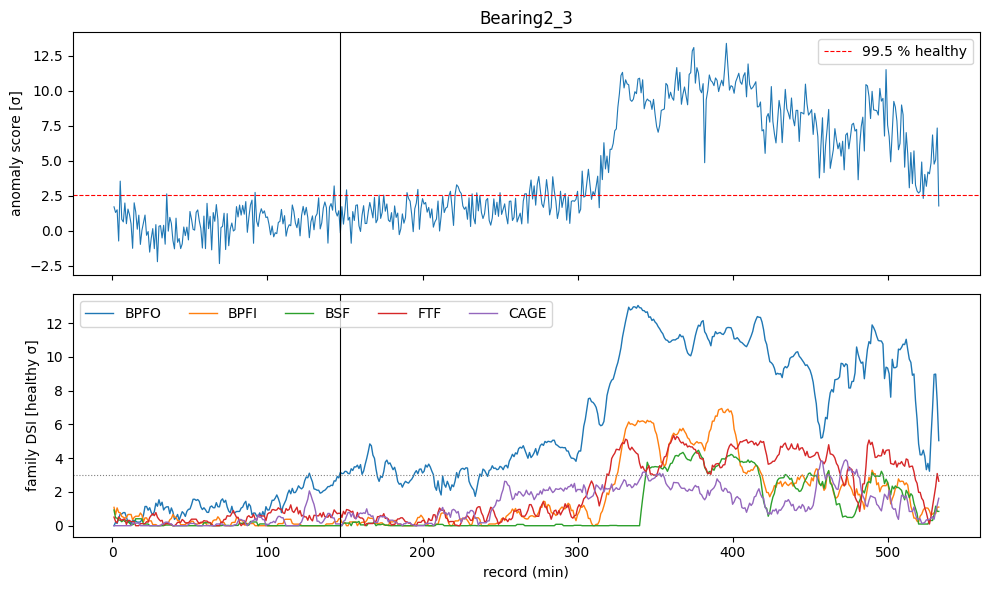

In [24]:
brng = 'Bearing2_3'
R = pd.read_csv(os.path.join(R4_OUT, f'{brng}.csv'), index_col='t')
fpt_t = R.index[R['fpt'] == 1][0] if R['fpt'].any() else None
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(R.index, R['score'], lw=0.8)
ax[0].axhline(Q995, color='r', ls='--', lw=0.8, label='99.5 % healthy')
ax[0].set_ylabel('anomaly score [σ]')
ax[0].legend()
for k in FAMILIES_DSI:
    ax[1].plot(R.index, R[k], lw=1, label=k)
ax[1].axhline(FAMILY_ALARM_THR, color='gray', ls=':', lw=0.8)
ax[1].set_ylabel('family DSI [healthy σ]')
ax[1].set_xlabel('record (min)')
ax[1].legend(ncol=5)
for a in ax:
    if fpt_t is not None:
        a.axvline(fpt_t, color='k', lw=0.8)
ax[0].set_title(brng)
fig.tight_layout()
plt.show()

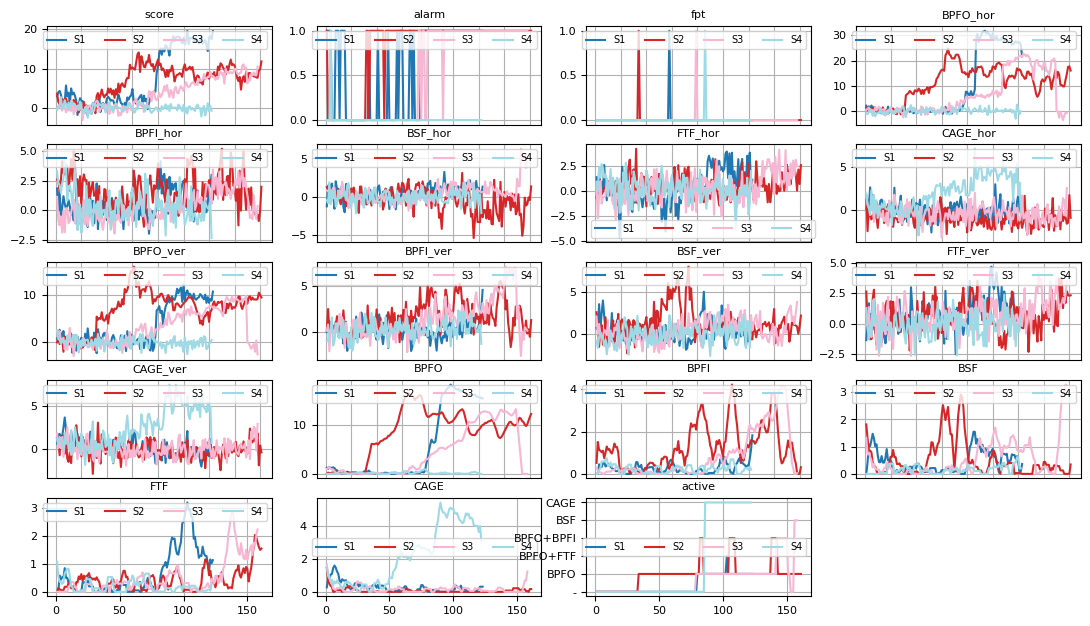

In [21]:
Ps = [r'Dataset\DSIR4\Bearing1_1.csv',r'Dataset\DSIR4\Bearing1_2.csv',r'Dataset\DSIR4\Bearing1_3.csv',r'Dataset\DSIR4\Bearing1_4.csv']
#Ps = [r'Dataset\DSIR4\Bearing2_1.csv',r'Dataset\DSIR4\Bearing2_2.csv',r'Dataset\DSIR4\Bearing2_3.csv',r'Dataset\DSIR4\Bearing2_4.csv']

Rs = [pd.read_csv(p, index_col='t') for p in Ps]

PlotFramesPLT(Rs)